# Lab 14 — Explaining Clinical Models: SHAP, Permutation Importance, and ECG Saliency Maps

**AI in Healthcare · Unit IV · B.Tech AI, Third Year · About 120 minutes**
**Lecture:** [Session 5 — Interpretability and explainability in clinical practice](../lectures/session-05-explainability-skills.md)
**Previous lab:** [Lab 13 — Validating a clinical prediction model](lab-13-model-validation.ipynb)
**Runs on:** a laptop CPU (the ECG model trains in a few minutes); a Kaggle notebook also works.

## Objectives

1. **Explain a tabular model two ways** — permutation importance (global) and SHAP (local) — and compare a logistic regression with a gradient-boosted model.
2. **Test whether two accurate models tell the same story** about the same patient.
3. **Compute saliency maps** for the Unit II ECG 1D CNN with three methods: gradient, gradient × input, and occlusion.
4. **Run a sanity check**: do the maps change when the model's weights are randomised?
5. **Test a suspected shortcut**: can beat length alone separate beat classes?

**Prerequisites:** Session 5 lecture notes (coefficients, contributions, permutation importance, saliency, sanity checks); the Unit II ECG lecture (beat classes N, S, V, F, Q; zero padding); Lab 13 (the heart-disease model and the four UCI sites). PyTorch basics: a forward pass and `.backward()`.

## Data

| | Part 1: heart disease | Part 2: ECG beats |
|---|---|---|
| Source | UCI Heart Disease, Cleveland and Budapest (CC BY 4.0, [doi:10.24432/C52P4X](https://doi.org/10.24432/C52P4X)) | MIT-BIH portion of the Kaggle [ECG Heartbeat Categorization Dataset](https://www.kaggle.com/datasets/shayanfazeli/heartbeat), derived from the [MIT-BIH Arrhythmia Database](https://physionet.org/content/mitdb/1.0.0/) |
| One row is | One patient | One beat: 187 values at 125 samples per second, zero-padded at the end |
| Size | About 50 KB, downloaded on first run | `mitbih_train.csv` (87,554 beats, about 393 MiB) and `mitbih_test.csv` (21,892 beats, about 98 MiB) — **not downloaded by this notebook** |

**Getting the ECG files.** The notebook looks, in order, in: any folder under `/kaggle/input/` (on Kaggle, add the dataset *shayanfazeli/heartbeat* to the notebook); `module2/lectures/data/ecg_hb_clf/` in this repository (where the Unit II notebooks keep it); `lab14_data/` next to this notebook, and the local Unit II lab folder `module 2/lab3/ecg/data/`. Check the Kaggle page's licence before redistributing the files.

## Deliverables

Submit the notebook run from top to bottom, with all `TODO` code completed, every ✍️ answer written, and the reflection in Part 3.

## Setup — 10 minutes

Libraries: NumPy, pandas, scikit-learn, matplotlib, SciPy, PyTorch and **SHAP**. SHAP is preinstalled on Kaggle; elsewhere, install it yourself before starting (`pip install shap`). The notebook never installs packages.

**Files written:** the two UCI files are cached in `lab14_data/` if downloaded. The notebook also checks the previous lab’s local UCI cache.

In [1]:
import time
import urllib.request
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
import torch
import torch.nn as nn
from scipy.stats import spearmanr
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, f1_score, roc_auc_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

try:
    import shap
except ImportError as err:
    raise ImportError("SHAP is not installed. Install it (pip install shap) and restart the kernel.") from err

SEED = 42
DATA_DIR = Path.cwd() / "lab14_data"
DATA_DIR.mkdir(exist_ok=True)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"scikit-learn {sklearn.__version__} | SHAP {shap.__version__} | torch {torch.__version__} | device {DEVICE}")


def check(description, condition):
    print(("PASS  " if condition else "CHECK ") + description)
if DEVICE.type == "cpu":
    torch.set_num_threads(min(4, torch.get_num_threads()))

scikit-learn 1.9.1 | SHAP 0.54.1 | torch 2.15.0+cpu | device cpu


/tmp/codex-lab14/packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Part 1 — Explaining the heart-disease model (40 minutes)

We reuse the Session 3–5 setup: eight inputs recorded at all four UCI sites, models trained on **Cleveland**, and the **Budapest** patients as external data for permutation importance. We compare two models:

- the **logistic regression** from Sessions 3–5;
- a **gradient-boosted tree ensemble** (many shallow decision trees added together), which can learn non-linear effects and interactions.

In [2]:
UCI_URL = "https://archive.ics.uci.edu/ml/machine-learning-databases/heart-disease/"
UCI_COLUMNS = ["age", "sex", "cp", "trestbps", "chol", "fbs", "restecg", "thalach",
               "exang", "oldpeak", "slope", "ca", "thal", "num"]
CORE = ["age", "sex", "cp", "trestbps", "thalach", "exang", "oldpeak", "restecg"]


def load_site(fname):
    path = DATA_DIR / fname
    if not path.exists():
        previous = Path.cwd().parent / "lab 1" / "lab13_data" / fname
        if previous.is_file():
            path = previous
        else:
            urllib.request.urlretrieve(UCI_URL + fname, path)
    df = pd.read_csv(path, header=None, names=UCI_COLUMNS, na_values="?")
    df["target"] = (df["num"] > 0).astype(int)
    return df


def design(df):
    x = df[CORE].copy()
    x[["cp", "restecg"]] = x[["cp", "restecg"]].astype(int)
    x = pd.get_dummies(x, columns=["cp", "restecg"], dtype=float)
    for col in ["cp_1", "cp_2", "cp_3", "cp_4", "restecg_0", "restecg_1", "restecg_2"]:
        if col not in x:
            x[col] = 0.0
    return x[sorted(x.columns)].drop(columns=["cp_1", "restecg_0"])


cle = load_site("processed.cleveland.data")
bud = load_site("processed.hungarian.data")
bud = bud[bud[CORE].notna().all(axis=1)].reset_index(drop=True)
X_cle, y_cle = design(cle), cle["target"].to_numpy()

MODELS = {
    "logistic regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)).fit(X_cle, y_cle),
    "gradient boosting": GradientBoostingClassifier(n_estimators=200, max_depth=2, learning_rate=0.05,
                                                    subsample=0.8, random_state=0).fit(X_cle, y_cle),
}
for name, model in MODELS.items():
    auc = roc_auc_score(bud["target"], model.predict_proba(design(bud))[:, 1])
    print(f"{name:20} Budapest AUROC {auc:.3f}")

logistic regression  Budapest AUROC 0.875
gradient boosting    Budapest AUROC 0.885


### Exercise 1.1 — Permutation importance on external data

Complete `permutation_importance_auroc`. For each **raw** input in `CORE`, shuffle that column of `df` (so a one-hot group such as chest-pain type moves together), recompute AUROC, and record the drop from the unshuffled AUROC. Repeat `n_repeats` times and return the mean drop and the 2.5th and 97.5th percentiles of the drops.

In [3]:
def permutation_importance_auroc(model, df, n_repeats=100, seed=SEED):
    rng = np.random.default_rng(seed)
    y = df["target"].to_numpy()
    base = roc_auc_score(y, model.predict_proba(design(df))[:, 1])
    rows = []
    for col in CORE:
        drops = []
        for _ in range(n_repeats):
            shuffled = df.copy()
            shuffled[col] = rng.permutation(df[col].to_numpy())
            shuffled_auc = roc_auc_score(y, model.predict_proba(design(shuffled))[:, 1])
            drops.append(base - shuffled_auc)
        low, high = np.percentile(drops, [2.5, 97.5])
        rows.append({"input": col, "mean drop": np.mean(drops),
                     "2.5%": low, "97.5%": high})
    return pd.DataFrame(rows).set_index("input").round(3)


importance = pd.concat({name: permutation_importance_auroc(m, bud) for name, m in MODELS.items()}, axis=1)
display(importance.sort_values(("logistic regression", "mean drop"), ascending=False))
check("chest-pain type matters for logistic regression",
      importance[("logistic regression", "mean drop")].get("cp", 0) > 0.03)

logistic regression               gradient boosting              
                   mean drop   2.5%  97.5%         mean drop   2.5%  97.5%
input                                                                     
cp                     0.066  0.042  0.093             0.084  0.055  0.119
oldpeak                0.037  0.024  0.051             0.047  0.031  0.064
sex                    0.027  0.009  0.051             0.020  0.007  0.037
exang                  0.017  0.009  0.026             0.015  0.007  0.024
thalach                0.004 -0.008  0.016             0.010 -0.005  0.031
age                   -0.002 -0.006  0.004             0.001 -0.005  0.005
trestbps              -0.002 -0.007  0.004             0.001 -0.009  0.008
restecg               -0.002 -0.006  0.002            -0.000 -0.002  0.001

PASS  chest-pain type matters for logistic regression


✍️ **Your answer** (3–4 sentences): Do the two models rely on the same inputs at Budapest? Which inputs could you remove without a measurable loss, judging by the percentile ranges? Why is "importance at Budapest" not the same as "importance for heart disease"?

**Answer.** Both models rely most on chest-pain type (`cp`) and `oldpeak`, with smaller positive drops for `sex` and `exang`. Boosting relies more on chest-pain type than logistic regression, with mean AUROC drops of 0.084 and 0.066, respectively. The permutation ranges for `thalach`, `age`, `trestbps`, and `restecg` span zero for both models, so these are candidates for removal followed by retraining and validation. The drops measure how each fitted model ranks patients from the Budapest cohort and depend on its case mix and correlated inputs, so they cannot establish which variables cause heart disease.

### Exercise 1.2 — SHAP for one patient

SHAP divides one prediction into additive contributions. For a tree ensemble, `shap.TreeExplainer` computes them exactly in the model's **log-odds** units:

$$\text{model log-odds} = \text{base value} + \sum_j \text{SHAP}_j$$

The patient is the first Cleveland record from Session 5: risk 0.60 under logistic regression, *no disease* on angiography. Complete the additivity check: add the base value and the SHAP values and compare with `decision_function`, which returns the gradient-boosted model's log-odds.

model log-odds: -0.225 | reconstructed: -0.22511390347869017
gradient-boosting risk: 0.444 | logistic-regression risk: 0.604
PASS  SHAP values add up to the model output


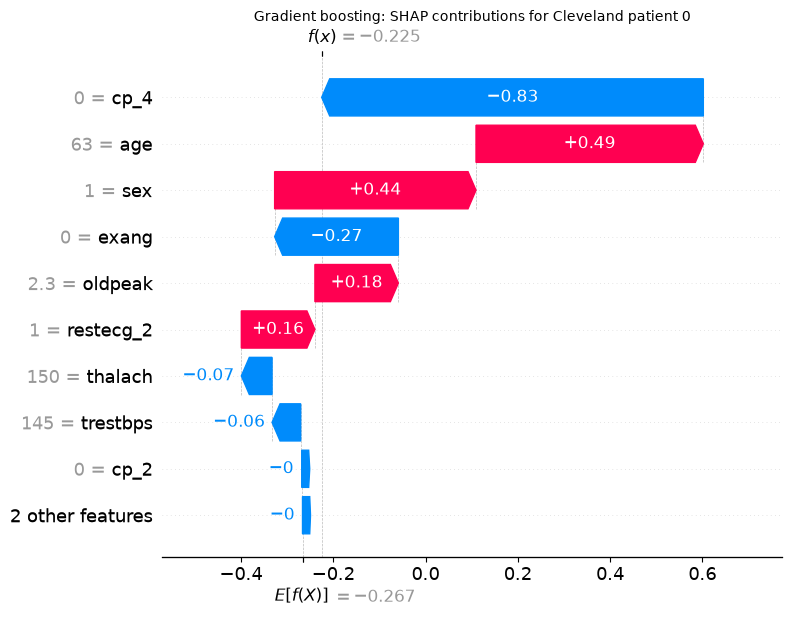

In [4]:
gb = MODELS["gradient boosting"]
explainer = shap.TreeExplainer(gb)
patient = X_cle.iloc[[0]]
sv = explainer(patient)                    # SHAP Explanation for one patient (log-odds units)

reconstructed = float(sv.base_values[0] + sv.values[0].sum())
model_log_odds = gb.decision_function(patient)[0]
print("model log-odds:", round(model_log_odds, 3), "| reconstructed:", reconstructed)
print("gradient-boosting risk:", round(gb.predict_proba(patient)[0, 1], 3),
      "| logistic-regression risk:", round(MODELS["logistic regression"].predict_proba(patient)[0, 1], 3))
check("SHAP values add up to the model output", abs(reconstructed - model_log_odds) < 1e-6)
shap.plots.waterfall(sv[0], show=False)
plt.title("Gradient boosting: SHAP contributions for Cleveland patient 0", fontsize=10)
plt.show()

In [5]:
# Logistic-regression contributions (Session 5): coefficient x standardised value
scaler, clf = MODELS["logistic regression"].named_steps.values()
lr_contrib = pd.Series(clf.coef_[0] * scaler.transform(patient)[0], index=X_cle.columns)
comparison = pd.DataFrame({"logistic regression": lr_contrib, "gradient boosting (SHAP)": sv.values[0]},
                          index=X_cle.columns).round(2)
comparison.sort_values("gradient boosting (SHAP)", key=abs, ascending=False)

,logistic regression,gradient boosting (SHAP)
cp_4,-1.01,-0.83
age,0.22,0.49
sex,0.54,0.44
exang,-0.26,-0.27
oldpeak,0.80,0.18
restecg_2,0.26,0.16
thalach,-0.01,-0.07
trestbps,0.23,-0.06
cp_2,-0.11,-0.00
cp_3,-0.05,-0.00


### Exercise 1.3 — Global SHAP view and two stories

The beeswarm plot below shows SHAP values for every Budapest patient: one dot per patient per input, coloured by the input's value (red high, blue low).

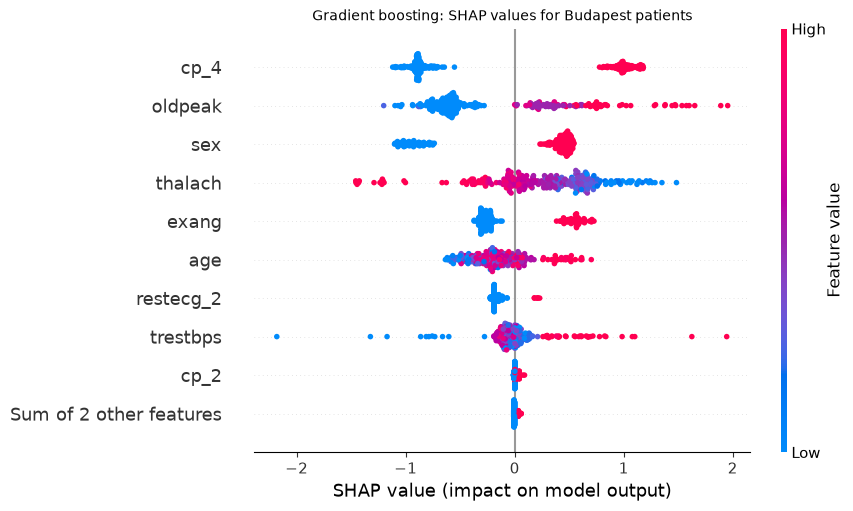

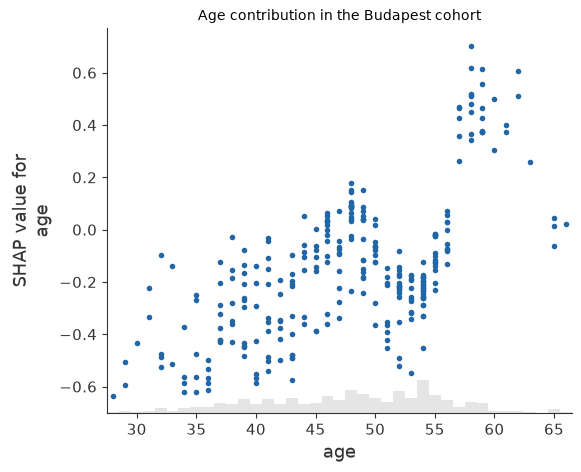

,median,min,max
age group,,,
"(0.0, 44.0]",-0.356,-0.636,0.054
"(44.0, 54.0]",-0.173,-0.549,0.178
"(54.0, 64.0]",0.304,-0.231,0.703
"(64.0, inf]",0.019,-0.064,0.045


In [6]:
sv_bud = explainer(design(bud))
shap.plots.beeswarm(sv_bud, show=False)
plt.title("Gradient boosting: SHAP values for Budapest patients", fontsize=10)
plt.show()
shap.plots.scatter(sv_bud[:, "age"], color="#2166a5", show=False)
plt.title("Age contribution in the Budapest cohort", fontsize=10)
plt.show()
age_effect = pd.DataFrame({
    "age group": pd.cut(bud["age"], bins=[0, 44, 54, 64, np.inf]),
    "age SHAP": sv_bud[:, "age"].values,
})
display(age_effect.groupby("age group", observed=True)["age SHAP"].agg(["median", "min", "max"]).round(3))

✍️ **Your answer** (5–7 sentences):

1. The two models have similar AUROC at Budapest. Do they give patient 0 the same risk and the same reasons? Which input does each model weight most for this patient?
2. Which explanation is "correct"? (Hint: each is exact for its own model.)
3. In the beeswarm, how does age affect the gradient-boosted model's output? Is the effect a straight line, as in logistic regression?
4. What does this mean for a clinician shown one model's explanation as "the reason" for a risk?

**Answer.** Budapest AUROCs were similar at 0.875 for logistic regression and 0.885 for boosting, yet the models gave Cleveland patient 0 risks of 60.4% and 44.4%, respectively. The largest absolute contribution in both was the `cp_4` indicator, which lowered the log-odds by 1.01 for logistic regression and by 0.83 for boosting. Their other contributions differed substantially, especially `oldpeak` (+0.80 versus +0.18) and age (+0.22 versus +0.49). Each decomposition is exact for its own model and baseline, and the boosting SHAP values reconstruct its −0.225 log-odds. Age usually lowered the boosting prediction at younger ages and raised it around ages 55–64, where the median SHAP value was +0.304, before falling near zero above age 64. This pattern varies between patients and is nonlinear, whereas logistic regression uses a constant slope for age on the log-odds scale. A clinician should read the attributions as a description of the fitted model’s score and interpret them alongside clinical evidence, including this patient’s negative angiogram.

## Part 2 — Saliency maps for the ECG 1D CNN (55 minutes)

### Load the beats and train the model

We retrain the Unit II architecture (four convolution blocks, global average pooling, two linear layers) for four epochs, using square-root class weights and keeping the epoch with the best validation macro-F1. On a laptop CPU each epoch takes about half a minute. Validation macro-F1 can go up and down between epochs; that is why the best epoch, not the last, is kept.

**Remember the limits of this dataset (Unit II):** rows are beats, not patients; the files contain no recording or patient IDs; and the source paper does not specify exactly where in the 187-sample window each beat was cut, so we locate the informative region from the data rather than assume it.

In [7]:
CANDIDATES = (sorted(Path("/kaggle/input").glob("**/mitbih_train.csv"))
              + [p / "module2/lectures/data/ecg_hb_clf/mitbih_train.csv" for p in (Path.cwd(), *Path.cwd().parents)]
              + [DATA_DIR / "mitbih_train.csv",
                 Path.cwd().parent.parent / "module 2" / "lab3" / "ecg" / "data" / "mitbih_train.csv"])
ECG_DIR = next((p.parent for p in CANDIDATES if p.is_file() and p.with_name("mitbih_test.csv").is_file()), None)
if ECG_DIR is None:
    raise FileNotFoundError("mitbih_train.csv not found. See 'Getting the ECG files' at the top of this notebook.")
print("ECG files found in folder:", ECG_DIR.name)

t0 = time.time()
train_arr = pd.read_csv(ECG_DIR / "mitbih_train.csv", header=None).to_numpy(np.float32)
test_arr = pd.read_csv(ECG_DIR / "mitbih_test.csv", header=None).to_numpy(np.float32)
X_tr_all, y_tr_all = train_arr[:, :187], train_arr[:, 187].astype(np.int64)
X_te, y_te = test_arr[:, :187], test_arr[:, 187].astype(np.int64)
CLASSES = ["N", "S", "V", "F", "Q"]
print(f"loaded in {time.time() - t0:.0f} s | train {len(X_tr_all):,} beats, test {len(X_te):,} beats")
print("training class counts:", dict(zip(CLASSES, np.bincount(y_tr_all))))
check("87,554 training beats", len(X_tr_all) == 87554)

X_fit, X_val, y_fit, y_val = train_test_split(X_tr_all, y_tr_all, test_size=0.1, stratify=y_tr_all, random_state=SEED)

ECG files found in folder: data


loaded in 3 s | train 87,554 beats, test 21,892 beats
training class counts: {'N': np.int64(72471), 'S': np.int64(2223), 'V': np.int64(5788), 'F': np.int64(641), 'Q': np.int64(6431)}
PASS  87,554 training beats


In [8]:
class ECGCNN(nn.Module):
    """Unit II architecture: input (n, 1, 187) -> 5 class logits."""
    def __init__(self, n_classes=5, base_filters=32, dropout=0.10):
        super().__init__()
        c1, c2, c3 = base_filters, base_filters * 2, base_filters * 4
        self.features = nn.Sequential(
            nn.Conv1d(1, c1, kernel_size=7, padding=3), nn.BatchNorm1d(c1), nn.ReLU(), nn.MaxPool1d(2), nn.Dropout(dropout / 2),
            nn.Conv1d(c1, c2, kernel_size=5, padding=2), nn.BatchNorm1d(c2), nn.ReLU(), nn.MaxPool1d(2), nn.Dropout(dropout),
            nn.Conv1d(c2, c3, kernel_size=5, padding=2), nn.BatchNorm1d(c3), nn.ReLU(), nn.MaxPool1d(2), nn.Dropout(dropout),
            nn.Conv1d(c3, c3, kernel_size=3, padding=1), nn.BatchNorm1d(c3), nn.ReLU(), nn.AdaptiveAvgPool1d(1))
        self.classifier = nn.Sequential(nn.Flatten(), nn.Linear(c3, 64), nn.ReLU(), nn.Dropout(dropout + 0.05),
                                        nn.Linear(64, n_classes))

    def forward(self, x):
        return self.classifier(self.features(x))


def to_tensor(x):
    return torch.from_numpy(np.ascontiguousarray(x)).unsqueeze(1)


@torch.no_grad()
def predict(model, x, batch=4096):
    model.eval()
    return np.concatenate([model(to_tensor(x[i:i + batch]).to(DEVICE)).argmax(1).cpu().numpy()
                           for i in range(0, len(x), batch)])


torch.manual_seed(SEED)
cnn = ECGCNN().to(DEVICE)
counts = np.bincount(y_fit)
loss_fn = nn.CrossEntropyLoss(weight=torch.tensor(np.sqrt(len(y_fit) / (5 * counts)), dtype=torch.float32).to(DEVICE))
optimizer = torch.optim.Adam(cnn.parameters(), lr=1e-3)
loader = torch.utils.data.DataLoader(torch.utils.data.TensorDataset(to_tensor(X_fit), torch.from_numpy(y_fit)),
                                     batch_size=256, shuffle=True, generator=torch.Generator().manual_seed(SEED))
best_f1, best_state = -1, None
for epoch in range(1, 5):
    t0 = time.time()
    cnn.train()
    for xb, yb in loader:
        optimizer.zero_grad()
        loss_fn(cnn(xb.to(DEVICE)), yb.to(DEVICE)).backward()
        optimizer.step()
    f1 = f1_score(y_val, predict(cnn, X_val), average="macro")
    print(f"epoch {epoch}: validation macro-F1 {f1:.3f} ({time.time() - t0:.0f} s)")
    if f1 > best_f1:
        best_f1, best_state = f1, {k: v.detach().clone() for k, v in cnn.state_dict().items()}
cnn.load_state_dict(best_state)
cnn.eval()
pred_te = predict(cnn, X_te)
print(classification_report(y_te, pred_te, target_names=CLASSES, digits=3))

epoch 1: validation macro-F1 0.830 (47 s)


epoch 2: validation macro-F1 0.717 (38 s)


epoch 3: validation macro-F1 0.847 (35 s)


epoch 4: validation macro-F1 0.834 (38 s)


              precision    recall  f1-score   support

           N      0.981     0.982     0.982     18118
           S      0.757     0.583     0.659       556
           V      0.908     0.936     0.922      1448
           F      0.482     0.827     0.609       162
           Q      0.988     0.961     0.975      1608

    accuracy                          0.966     21892
   macro avg      0.823     0.858     0.829     21892
weighted avg      0.968     0.966     0.966     21892



### Where do the classes differ?

Before looking at saliency, look at the data. The plot shows the mean N beat and mean V beat in the test set, and where they differ most. A saliency method that highlights *these* positions is at least consistent with the data.

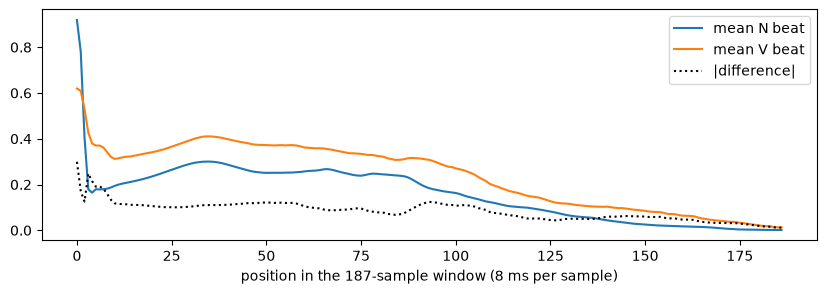

positions of largest N-V difference: [0 3 4 6 5 7 1 8]


In [9]:
mean_n, mean_v = X_te[y_te == 0].mean(0), X_te[y_te == 2].mean(0)
fig, ax = plt.subplots(figsize=(10, 3))
ax.plot(mean_n, label="mean N beat"); ax.plot(mean_v, label="mean V beat")
ax.plot(np.abs(mean_n - mean_v), "k:", label="|difference|")
ax.set_xlabel("position in the 187-sample window (8 ms per sample)"); ax.legend()
plt.show()
print("positions of largest N-V difference:", np.argsort(-np.abs(mean_n - mean_v))[:8])

### Exercise 2.1 — Gradient and gradient × input

`gradient_map` returns $\partial\,\text{logit}_c / \partial x_t$ for each beat and position. Complete `grad_x_input_map`, which multiplies the gradient by the input value.

In [10]:
V = CLASSES.index("V")
idx_v = np.flatnonzero((y_te == V) & (pred_te == V))[:200]      # 200 correctly classified V beats
beats_v = X_te[idx_v]


def gradient_map(model, x, c):
    model.eval()
    xb = to_tensor(x).to(DEVICE).requires_grad_(True)
    gradient, = torch.autograd.grad(model(xb)[:, c].sum(), xb)
    return gradient.squeeze(1).cpu().numpy()


def grad_x_input_map(model, x, c):
    return gradient_map(model, x, c) * x


g_map = gradient_map(cnn, beats_v, V)
gi_map = grad_x_input_map(cnn, beats_v, V)
check("gradient x input differs from zero", np.abs(gi_map).sum() > 0)

PASS  gradient x input differs from zero


### Exercise 2.2 — Occlusion

Complete `occlusion_map`: slide a window of `width` samples along the beat in steps of `stride`, set the window to 0, and record the **drop in the predicted probability** of class `c`. Average the drops over all windows covering each position.

In [11]:
@torch.no_grad()
def class_prob(model, x, c):
    model.eval()
    return torch.softmax(model(to_tensor(x).to(DEVICE)), dim=1)[:, c].cpu().numpy()


def occlusion_map(model, x, c, width=10, stride=2):
    if not 1 <= stride <= width <= x.shape[1]:
        raise ValueError("Require 1 <= stride <= width <= beat size.")
    base = class_prob(model, x, c)
    total = np.zeros_like(x)
    covered = np.zeros(x.shape[1])
    last_start = x.shape[1] - width
    starts = list(range(0, last_start + 1, stride))
    if starts[-1] != last_start:
        starts.append(last_start)
    for start in starts:
        window = slice(start, start + width)
        occluded = x.copy()
        occluded[:, window] = 0
        total[:, window] += (base - class_prob(model, occluded, c))[:, None]
        covered[window] += 1
    return total / np.maximum(covered, 1)


o_map = occlusion_map(cnn, beats_v, V)
check("occlusion found some important positions", o_map.max() > 0.05)

PASS  occlusion found some important positions


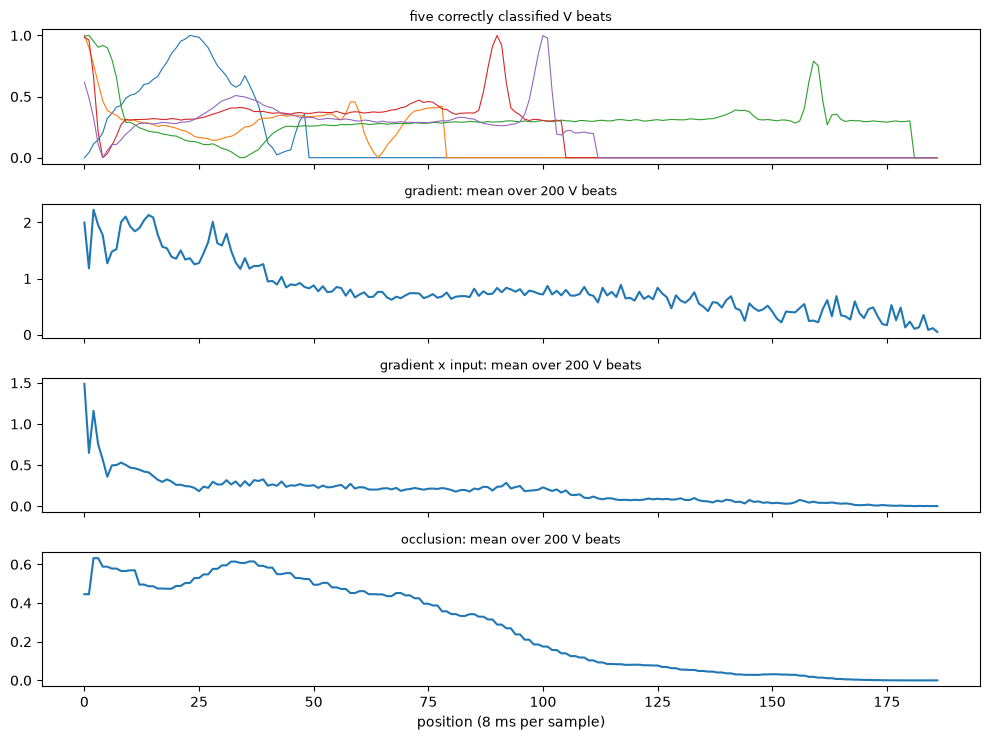

padding is 41% of all positions in these beats


,share of map on padding,top positions
gradient,0.224202,"[2, 14, 9, 15, 13]"
gradient x input,0.0,"[0, 2, 3, 1, 4]"
occlusion,0.001124,"[3, 2, 36, 37, 33]"


In [12]:
def beat_length(x):
    positions = np.arange(1, x.shape[1] + 1)
    return np.where(x != 0, positions, 0).max(axis=1, initial=0)


def padding_mask(x):
    """True for the zero padding after the last non-zero sample of each beat."""
    return np.arange(x.shape[1])[None, :] >= beat_length(x)[:, None]


pad = padding_mask(beats_v)
maps = {"gradient": np.abs(g_map), "gradient x input": np.abs(gi_map), "occlusion": np.clip(o_map, 0, None)}
fig, axes = plt.subplots(len(maps) + 1, 1, figsize=(10, 7.5), sharex=True)
axes[0].plot(beats_v[:5].T, lw=0.8); axes[0].set_title("five correctly classified V beats", fontsize=9)
for ax, (name, m) in zip(axes[1:], maps.items()):
    ax.plot(m.mean(0)); ax.set_title(f"{name}: mean over 200 V beats", fontsize=9)
axes[-1].set_xlabel("position (8 ms per sample)")
plt.tight_layout(); plt.show()

summary = pd.DataFrame({name: {"share of map on padding": (m * pad).sum() / m.sum(),
                               "top positions": list(np.argsort(-m.mean(0))[:5])}
                        for name, m in maps.items()}).T
print(f"padding is {pad.mean():.0%} of all positions in these beats")
summary

✍️ **Your answer** (4–5 sentences): Where do the three methods put most of the importance? Does that agree with where the mean N and V beats differ? The gradient map puts some weight on the zero padding while gradient × input and occlusion put almost none there — explain why from how each method is computed.

**Answer.** All three methods highlight positions early in the beat, with top positions 2, 14, and 9 for the gradient, 0, 2, and 3 for gradient × input, and 3 and 2 for occlusion, which also highlights positions 33–37. The mean N–V difference peaks within positions 0–8, so the gradient × input peaks overlap most closely and occlusion partly agrees. Padding accounts for 41% of the sampled positions and receives 22.4% of the absolute gradient mass because the derivative at a zero-valued sample can still be nonzero. Gradient × input gives padding exactly zero weight because it multiplies the derivative by zero. Occlusion puts just 0.11% of its positive mass on padding because a window entirely within padding leaves the input unchanged, while a window that straddles the boundary can spread a probability drop across both signal and padding.

### Exercise 2.3 — Sanity check: randomise the model

Adebayo et al. (2018) asked: if we destroy what the model learned, does the map change? Below, an **untrained** network with random weights is created. Complete `sanity_check`: for each beat, compute the Spearman rank correlation between the absolute map from the trained model and from the random model, and return the median. A correlation near 1 means the map barely depends on what the model learned.

In [13]:
torch.manual_seed(123)
random_cnn = ECGCNN().to(DEVICE).eval()

METHODS = {"gradient": lambda m: np.abs(gradient_map(m, beats_v, V)),
           "gradient x input": lambda m: np.abs(grad_x_input_map(m, beats_v, V)),
           "occlusion": lambda m: np.abs(occlusion_map(m, beats_v, V))}


def sanity_check(method):
    trained, randomised = METHODS[method](cnn), METHODS[method](random_cnn)
    # Spearman correlation is undefined if either map is constant.
    correlations = [
        spearmanr(a, b).statistic
        for a, b in zip(trained, randomised)
        if np.ptp(a) > 0 and np.ptp(b) > 0
    ]
    return float(np.median(correlations)) if correlations else np.nan


sanity = pd.Series({name: sanity_check(name) for name in METHODS}, name="median Spearman (trained vs random)")
sanity

gradient            0.026125
gradient x input    0.830089
occlusion           0.860494
Name: median Spearman (trained vs random), dtype: float64

✍️ **Your answer** (3–4 sentences): Which method fails the sanity check? Why might gradient × input look similar for a trained and a random network? (Hint: what does it multiply by?) Which method would you trust most for this model, and why?

**Answer.** Gradient × input and occlusion both showed high similarity after randomization, with median Spearman correlations of 0.830 and 0.860, so both performed poorly on this check. Gradient × input uses the same ECG amplitudes for both networks, and the shared zero padding and large waveform peaks can dominate the ranks. With zero-baseline occlusion, padding-only windows produce no change for either model, which can also preserve a common rank pattern. I would put the most weight on the raw gradient for detecting learned sensitivity because its median correlation was 0.026, while checking its substantial padding attribution before interpreting the highlighted samples.

### Exercise 2.4 — Test a suspected shortcut: beat length

Beats are zero-padded to 187 samples, so a beat's **length** (position of its last non-zero sample) is visible to the model. If length alone separated classes, the model could use it as a shortcut. Complete the cell: compute the length of every beat, show the median length by class, and fit a logistic regression on length alone to separate V from N (train on `X_fit`, evaluate AUROC on the test set).

In [14]:
len_fit, len_te = beat_length(X_fit), beat_length(X_te)
print(pd.Series(len_te).groupby(pd.Series(y_te).map(dict(enumerate(CLASSES)))).median().rename("median length"))

fit_nv = np.isin(y_fit, [0, V])
test_nv = np.isin(y_te, [0, V])
length_model = LogisticRegression().fit(len_fit[fit_nv, None], y_fit[fit_nv] == V)
length_scores = length_model.predict_proba(len_te[test_nv, None])[:, 1]
auroc_length = roc_auc_score(y_te[test_nv] == V, length_scores)
print("V vs N AUROC from beat length alone:", f"{auroc_length:.3f}")

F     78.0
N    106.0
Q    120.0
S    108.0
V    112.0
Name: median length, dtype: float64


V vs N AUROC from beat length alone: 0.551


✍️ **Your answer** (3–4 sentences): Is beat length a strong shortcut for V versus N? Is it for any other class (look at the medians)? What does this test add that the saliency maps alone could not tell you?

**Answer.** Beat length alone is a weak shortcut for V versus N because its held-out AUROC of 0.551 is close to chance, and their median lengths are 112 and 106 samples. F has the shortest median (78 samples) and Q the longest (120), so length could be more informative for pairs such as F versus Q, although the medians alone cannot establish how well they separate. The length-only model directly tests how much discrimination one preprocessing cue can provide on unseen beats, while saliency shows sensitivity of the trained CNN to specific samples. The near-chance V–N result still leaves open whether the CNN uses length together with morphology.

## Part 3 — Reflection (15 minutes)

✍️ **Your answer** (8–10 sentences):

1. A hospital wants to show SHAP explanations next to each heart-disease risk "so clinicians can see why". Using Part 1, write two cautions for them.
2. A colleague shows you an attractive gradient × input saliency map for an ECG model as evidence that "the model looks at the right place". Using Part 2, what would you ask them to do first?
3. For which purpose in Session 5's table were the methods in this lab most useful: finding problems during development, auditing, bedside explanation, or proof of correctness? Give one example from your results.

**Answer.** First, a hospital should label SHAP values as contributions to the output of a specific fitted model and state the reference baseline and log-odds units. The two models achieved Budapest AUROCs of 0.875 and 0.885, yet assigned the same angiography-negative patient risks of 60.4% and 44.4% and gave `oldpeak` different weight. Second, the hospital should validate calibration and performance in its own patient population before displaying the scores as clinical risks. Attribution additivity verifies the arithmetic of a prediction, while calibration and causal relevance require separate evidence. For the ECG map, my first request would be to randomize the CNN weights and compare maps for the same beats against the trained model’s maps. Here the gradient × input ranks still had a median correlation of 0.830, so their visual agreement with the waveform is weak evidence that the CNN learned to focus on that region. I would also check how much of that similarity remains when the padded samples are excluded from the comparison. These methods were most useful for finding problems during development, such as detecting a saliency method that retained much of its ranking after the model weights were randomized. The length-only AUROC of 0.551 then helped narrow the V-versus-N shortcut hypothesis, although the beat-level split leaves patient-level generalization unverified.

## Grading rubric

| Criterion | Points |
|---|---:|
| Part 1: permutation importance implemented with grouped inputs and repeat ranges; interpretation | 20 |
| Part 1: SHAP additivity check; comparison of the two models' explanations; non-linear effect described | 20 |
| Part 2: gradient × input and occlusion implemented; maps compared with where classes differ; padding behaviour explained | 25 |
| Part 2: sanity check implemented and interpreted; beat-length shortcut tested | 20 |
| Part 3: reflection that is specific, uses results, and does not over-claim | 15 |
| **Total** | **100** |

These points apply to this lab only. They are not course-assessment weights.

## References

- [Session 5 lecture notes](../lectures/session-05-explainability-skills.md).
- Lundberg SM, Lee S-I. [A unified approach to interpreting model predictions](https://arxiv.org/abs/1705.07874). *NeurIPS* 2017. — SHAP; [SHAP documentation](https://shap.readthedocs.io/).
- Adebayo J et al. [Sanity checks for saliency maps](https://arxiv.org/abs/1810.03292). *NeurIPS* 2018.
- Zeiler MD, Fergus R. [Visualizing and understanding convolutional networks](https://arxiv.org/abs/1311.2901). *ECCV* 2014. — occlusion.
- Kachuee M, Fazeli S, Sarrafzadeh M. [ECG heartbeat classification: a deep transferable representation](https://arxiv.org/abs/1805.00794). 2018. — source of the processed beats.
- UCI Machine Learning Repository. [Heart Disease dataset](https://archive.ics.uci.edu/dataset/45/heart+disease) (doi:10.24432/C52P4X), CC BY 4.0.